# LBM viewer

Reads the binary frames exported by `lbm2d` using `resultados/airfoil/metadata.json`.

In [ ]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

# Change this before rerunning the cell to inspect another case, e.g.
# DATA_DIR = '../resultados/sports_car', '../resultados/formula1', or '../resultados/smoke_formula1'
data_dir = Path(globals().get('DATA_DIR', '../resultados/airfoil'))
metadata_path = data_dir / 'metadata.json'
with metadata_path.open() as f:
    meta = json.load(f)

nx = int(meta['nx'])
ny = int(meta['ny'])
fields = list(meta['fields'])
frame_dir = data_dir / 'frames'

meta

{'case_name': 'naca2412_aoa6_ultra',
 'nx': 768,
 'ny': 320,
 'dx': 1,
 'dt': 1,
 'dtype': 'float32',
 'layout': 'row-major',
 'index_formula': 'index = x + nx * y',
 'fields': ['rho', 'ux', 'uy', 'pressure', 'vorticity', 'solid', 'phi'],
 'frame_stride': 4,
 'force_stride': 4,
 'diagnostics_stride': 4,
 'steps': 1440,
 'frames_written': 361,
 'rho0': 1,
 'u_in': 0.032,
 'tau': 0.62,
 'omega': 1.6129032258064517,
 'viscosity': 0.04,
 'reynolds': 192,
 'start_from_rest': True,
 'inlet_ramp_steps': 240,
 'boundary_mode': 'open_flow',
 'obstacle': {'type': 'airfoil',
  'center_x': 322.56,
  'center_y': 160,
  'radius': 20,
  'half_width': 30,
  'half_height': 12,
  'angle_degrees': 6,
  'airfoil_chord': 240,
  'airfoil_max_camber': 0.02,
  'airfoil_camber_position': 0.4,
  'airfoil_max_thickness': 0.12,
  'airfoil_samples': 700}}

In [ ]:
def list_frames():
    return sorted(frame_dir.glob('frame_*.bin'))

def read_frame(path=None):
    frames = list_frames()
    if not frames:
        raise FileNotFoundError(f'No frames found in {frame_dir}')
    if path is None:
        path = frames[-1]
    path = Path(path)
    raw = np.fromfile(path, dtype=np.float32)
    cells = nx * ny
    expected = cells * len(fields)
    if raw.size != expected:
        raise ValueError(f'{path.name}: expected {expected} floats, got {raw.size}')
    arrays = {}
    for i, name in enumerate(fields):
        start = i * cells
        arrays[name] = raw[start:start + cells].reshape(ny, nx)
    return arrays, path

arrays, frame_path = read_frame()
frame_path.name, arrays.keys()

('frame_001440.bin',
 dict_keys(['rho', 'ux', 'uy', 'pressure', 'vorticity', 'solid', 'phi']))

In [ ]:
frame_paths = list_frames()
frame_cache = {}
u_in = float(meta.get('u_in', 1.0))
ramp_steps = int(meta.get('inlet_ramp_steps', 0))
wall_band_cells = 12.0

def frame_step(path):
    return int(Path(path).stem.split('_')[-1])

def inlet_velocity_for_step(step):
    if ramp_steps <= 0:
        return u_in
    t = np.clip(step / ramp_steps, 0.0, 1.0)
    smooth = t * t * (3.0 - 2.0 * t)
    return u_in * smooth

def display_cmap(name):
    cmap = plt.get_cmap(name).copy()
    cmap.set_bad(color='0.82')
    return cmap

def display_mask(frame_arrays, field_name, hide_wall_band=True, wall_band=wall_band_cells):
    solid = frame_arrays['solid'] > 0.5
    if hide_wall_band and field_name not in ('solid', 'phi', 'vorticity'):
        return solid | (frame_arrays['phi'] < wall_band)
    return solid

def crop_limits(frame_arrays, mode='airfoil+wake'):
    solid = frame_arrays['solid'] > 0.5
    ys, xs = np.where(solid)
    if mode == 'full' or xs.size == 0:
        return None
    xmin, xmax = int(xs.min()), int(xs.max())
    ymin, ymax = int(ys.min()), int(ys.max())
    chord_px = max(1, xmax - xmin + 1)
    height_px = max(1, ymax - ymin + 1)
    if mode == 'airfoil':
        pad_x0, pad_x1 = int(0.35 * chord_px), int(0.45 * chord_px)
        pad_y = int(3.2 * height_px)
    else:
        pad_x0, pad_x1 = int(0.45 * chord_px), int(1.75 * chord_px)
        pad_y = int(4.0 * height_px)
    return (
        max(0, xmin - pad_x0),
        min(nx - 1, xmax + pad_x1),
        max(0, ymin - pad_y),
        min(ny - 1, ymax + pad_y),
    )

def flow_reference(frame_arrays, limits=None, wall_band=wall_band_cells):
    solid = frame_arrays['solid'] > 0.5
    speed = np.hypot(frame_arrays['ux'], frame_arrays['uy'])
    if limits is None:
        x0, x1, y0, y1 = 0, nx - 1, 0, ny - 1
    else:
        x0, x1, y0, y1 = limits
    ys, xs = np.where(solid)
    if xs.size:
        xmin = int(xs.min())
        xmax = int(xs.max())
        chord_px = max(1, xmax - xmin + 1)
        ref_x1 = max(x0, min(x1, xmin - int(0.12 * chord_px)))
    else:
        ref_x1 = x0 + max(1, int(0.25 * (x1 - x0 + 1)))
    region = np.s_[y0:y1 + 1, x0:ref_x1 + 1]
    mask = solid[region] | (frame_arrays['phi'][region] < wall_band)
    values = np.ma.array(speed[region], mask=mask).compressed()
    values = values[np.isfinite(values)]
    values = values[values > max(0.04 * abs(u_in), 1.0e-8)]
    if values.size >= 16:
        return float(np.nanmedian(values))
    return max(abs(u_in), 1.0e-6)

def plot_flow_overlay(ax, frame_arrays, limits, mode='streamlines', wall_band=0.0, step_index=0):
    if mode == 'none':
        return
    reference_u = inlet_velocity_for_step(step_index)
    if abs(reference_u) <= 1.0e-8:
        return
    if limits is None:
        x0, x1, y0, y1 = 0, nx - 1, 0, ny - 1
    else:
        x0, x1, y0, y1 = limits
    u_ref = flow_reference(frame_arrays, limits, wall_band)
    width = max(1, x1 - x0 + 1)
    height = max(1, y1 - y0 + 1)
    step = max(3, int(max(width, height) / 90))
    xs = np.arange(x0, x1 + 1, step)
    ys = np.arange(y0, y1 + 1, step)
    if xs.size < 2 or ys.size < 2:
        return
    ux = frame_arrays['ux'][y0:y1 + 1:step, x0:x1 + 1:step]
    uy = frame_arrays['uy'][y0:y1 + 1:step, x0:x1 + 1:step]
    speed = np.hypot(ux, uy)
    mask = (frame_arrays['solid'][y0:y1 + 1:step, x0:x1 + 1:step] > 0.5)
    if wall_band > 0.0:
        mask = mask | (frame_arrays['phi'][y0:y1 + 1:step, x0:x1 + 1:step] < wall_band)
    wind_threshold = max(0.22 * abs(u_ref), 0.04 * abs(u_in), 1.0e-8)
    mask = mask | (speed < wind_threshold)
    if np.count_nonzero(~mask) < 8:
        return
    ux = np.ma.array(ux, mask=mask)
    uy = np.ma.array(uy, mask=mask)
    if mode == 'quiver':
        qstep = max(1, int(max(width, height) / 35 / step))
        ax.quiver(xs[::qstep], ys[::qstep], ux[::qstep, ::qstep], uy[::qstep, ::qstep], color='black', alpha=0.55, scale_units='xy', angles='xy', scale=max(0.006, 0.22 * u_ref), width=0.0022)
        return
    ax.streamplot(xs, ys, ux, uy, color='black', density=0.95, linewidth=0.55, arrowsize=0.65, minlength=0.12, maxlength=3.2)

def cached_frame(frame_index):
    frame_index = int(frame_index)
    if frame_index not in frame_cache:
        frame_cache[frame_index] = read_frame(frame_paths[frame_index])
    return frame_cache[frame_index]

def scalar_view(frame_arrays, field_name, step):
    reference_u = inlet_velocity_for_step(step)
    speed = np.hypot(frame_arrays['ux'], frame_arrays['uy'])
    denom = max(abs(reference_u), 1.0e-6)
    nominal = max(abs(u_in), 1.0e-6)
    solid = frame_arrays['solid'] > 0.5
    if field_name in ('local_speed_delta', 'local_ux_delta'):
        scale = max(abs(reference_u), 0.35 * nominal, 1.0e-6)
        base_field = speed if field_name == 'local_speed_delta' else frame_arrays['ux']
        fluid_values = np.where(solid, np.nan, base_field)
        background = np.nanmedian(fluid_values, axis=0)
        background = np.where(np.isfinite(background), background, 0.0)
        return (base_field - background[None, :]) / scale
    if field_name == 'relative_speed_red':
        scale = max(abs(reference_u), 0.35 * nominal, 1.0e-6)
        fluid_speed = np.where(solid, np.nan, speed)
        background = np.nanmedian(fluid_speed, axis=0)
        background = np.where(np.isfinite(background), background, 0.0)
        return np.abs(speed - background[None, :]) / scale
    if field_name == 'wind_speed_red':
        scale = max(abs(reference_u), 0.35 * nominal, 1.0e-6)
        return speed / scale
    if field_name == 'speed':
        return speed
    if field_name == 'speed_delta':
        if abs(reference_u) <= 1.0e-6:
            return speed / nominal
        return speed / denom - 1.0
    if field_name == 'relative_speed':
        return np.hypot(frame_arrays['ux'] - reference_u, frame_arrays['uy'])
    if field_name == 'speed_ratio':
        if abs(reference_u) <= 1.0e-6:
            return speed / nominal
        return speed / denom
    if field_name == 'ux_deficit':
        if abs(reference_u) <= 1.0e-6:
            return np.zeros_like(frame_arrays['ux'])
        return 1.0 - frame_arrays['ux'] / denom
    if field_name == 'wake_deficit':
        return reference_u - frame_arrays['ux']
    return frame_arrays[field_name]

def visible_values(masked, limits):
    if limits is None:
        values = masked.compressed()
    else:
        x0, x1, y0, y1 = limits
        values = masked[y0:y1 + 1, x0:x1 + 1].compressed()
    return values[np.isfinite(values)]

def contrast_limits(values, low=2.0, high=98.5, contrast=1.0, floor_width=1.0e-6):
    if values.size == 0:
        return 0.0, 1.0
    lo, hi = np.nanpercentile(values, [low, high])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        center = float(np.nanmedian(values)) if values.size else 0.0
        return center - 0.5, center + 0.5
    center = 0.5 * (lo + hi)
    half_width = max(0.5 * (hi - lo) / max(contrast, 1.0e-6), floor_width)
    return center - half_width, center + half_width

def mark_extremes(ax, masked, limits, enabled=True):
    if not enabled:
        return
    values = visible_values(masked, limits)
    values = values[np.isfinite(values)]
    if values.size < 32:
        return
    negative = values[values < 0.0]
    positive = values[values > 0.0]
    if positive.size:
        level = max(0.06, np.nanpercentile(positive, 72))
        upper = max(float(np.nanmax(positive)), level + 1.0e-6)
        if upper > level:
            ax.contour(masked, levels=[level], colors=['#7f0000'], linewidths=1.15, alpha=0.9)
            ax.contourf(masked, levels=[level, upper], colors=['#ff3b1f'], alpha=0.10)
    if negative.size:
        level = min(-0.06, np.nanpercentile(negative, 28))
        lower = min(float(np.nanmin(negative)), level - 1.0e-6)
        if level > lower:
            ax.contour(masked, levels=[level], colors=['#08306b'], linewidths=1.15, alpha=0.9)
            ax.contourf(masked, levels=[lower, level], colors=['#1f78ff'], alpha=0.10)

def plot_frame(frame_index=0, field_name='speed_deviation', view_mode='airfoil+wake', overlay_mode='quiver', hide_wall_band=True, wall_band=12.0, contrast=0.28):
    frame_arrays, path = cached_frame(frame_index)
    step = frame_step(path)
    limits = crop_limits(frame_arrays, view_mode)
    if field_name == 'speed_deviation':
        speed = np.hypot(frame_arrays['ux'], frame_arrays['uy'])
        u_ref = flow_reference(frame_arrays, limits, wall_band)
        data = speed / max(abs(u_ref), 1.0e-6) - 1.0
    else:
        data = scalar_view(frame_arrays, field_name, step)
    mask = display_mask(frame_arrays, field_name, hide_wall_band, wall_band)
    solid = frame_arrays['solid'] > 0.5
    masked = np.ma.array(data, mask=mask if field_name != 'solid' else None)

    cmap = display_cmap('viridis')
    vmin = vmax = None
    if field_name == 'speed_deviation':
        cmap = display_cmap('RdBu_r')
        vmin, vmax = -contrast, contrast
    elif field_name in ('vorticity', 'ux', 'uy', 'wake_deficit', 'speed_delta', 'ux_deficit', 'local_speed_delta', 'local_ux_delta'):
        cmap = display_cmap('coolwarm')
        values = np.abs(masked.compressed())
        limit = np.nanpercentile(values, 99.5) if values.size else 1.0
        if field_name == 'speed_delta':
            limit = min(max(limit, 0.08), 0.55)
        elif field_name in ('local_speed_delta', 'local_ux_delta'):
            limit = min(max(limit, 0.05), 0.35)
        elif field_name == 'ux_deficit':
            limit = min(max(limit, 0.08), 0.80)
        vmin, vmax = -limit, limit
    elif field_name == 'relative_speed':
        cmap = display_cmap('magma')
        values = np.abs(masked.compressed())
        vmax = np.nanpercentile(values, 99) if values.size else 1.0
        vmin = 0.0
    elif field_name == 'relative_speed_red':
        cmap = display_cmap('inferno')
        values = np.abs(visible_values(masked, limits))
        vmax = np.nanpercentile(values, 99.5) / max(contrast, 1.0e-6) if values.size else 0.35
        vmax = min(max(vmax, 0.025), 0.55)
        vmin = 0.0
    elif field_name == 'wind_speed_red':
        cmap = display_cmap('inferno')
        values = visible_values(masked, limits)
        vmin, vmax = contrast_limits(values, low=3.0, high=99.0, contrast=max(contrast, 0.05), floor_width=0.015)
    elif field_name == 'speed_ratio':
        cmap = display_cmap('viridis')
        vmin, vmax = 0.0, 1.35

    fig, ax = plt.subplots(figsize=(9, 3.8), constrained_layout=True)
    im = ax.imshow(masked, origin='lower', cmap=cmap, vmin=vmin, vmax=vmax, interpolation='bicubic')
    if field_name == 'speed_deviation':
        mark_extremes(ax, masked, limits, enabled=True)
    ax.contour(solid.astype(float), levels=[0.5], colors='black', linewidths=0.9)
    if limits is not None:
        x0, x1, y0, y1 = limits
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
    plot_flow_overlay(ax, frame_arrays, limits, overlay_mode, wall_band if hide_wall_band else 0.0, step)
    ax.set_title(f'{field_name} - {path.name} - Uin={inlet_velocity_for_step(step):.4f}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    plt.show()

field_options = ['speed_deviation', 'wind_speed_red', 'relative_speed_red', 'speed', 'vorticity', 'local_speed_delta', 'local_ux_delta', 'speed_delta', 'ux_deficit', 'speed_ratio', 'relative_speed', 'wake_deficit'] + [name for name in fields if name not in ('solid', 'phi')]

try:
    import ipywidgets as widgets
    from IPython.display import display

    frame_slider = widgets.IntSlider(
        value=len(frame_paths) - 1,
        min=0,
        max=len(frame_paths) - 1,
        step=1,
        description='frame',
        continuous_update=False,
        layout=widgets.Layout(width='520px'),
    )
    play = widgets.Play(value=0, min=0, max=len(frame_paths) - 1, step=1, interval=220)
    widgets.jslink((play, 'value'), (frame_slider, 'value'))
    field_dropdown = widgets.Dropdown(options=field_options, value='speed_deviation', description='field')
    view_dropdown = widgets.Dropdown(options=['airfoil+wake', 'airfoil', 'full'], value='airfoil+wake', description='view')
    overlay_dropdown = widgets.Dropdown(options=['quiver', 'streamlines', 'none'], value='quiver', description='flow')
    wall_toggle = widgets.Checkbox(value=True, description='hide wall band')
    wall_slider = widgets.FloatSlider(value=12.0, min=0.0, max=28.0, step=0.5, description='wall band', continuous_update=False, layout=widgets.Layout(width='360px'))
    contrast_slider = widgets.FloatSlider(value=0.28, min=0.08, max=0.70, step=0.02, description='range', continuous_update=False, layout=widgets.Layout(width='360px'))
    controls = widgets.VBox([
        widgets.HBox([play, frame_slider, field_dropdown]),
        widgets.HBox([view_dropdown, overlay_dropdown, wall_toggle, wall_slider]),
        widgets.HBox([contrast_slider]),
    ])
    out = widgets.interactive_output(
        plot_frame,
        {'frame_index': frame_slider, 'field_name': field_dropdown, 'view_mode': view_dropdown, 'overlay_mode': overlay_dropdown, 'hide_wall_band': wall_toggle, 'wall_band': wall_slider, 'contrast': contrast_slider},
    )
    display(controls, out)
except Exception as exc:
    from matplotlib.animation import FuncAnimation
    from IPython.display import HTML, display

    fig, ax = plt.subplots(figsize=(9, 3.8), constrained_layout=True)
    first_arrays, _ = cached_frame(0)
    first_speed = scalar_view(first_arrays, 'local_speed_delta', 0)
    solid = first_arrays['solid'] > 0.5
    first_mask = display_mask(first_arrays, 'local_speed_delta', True)
    im = ax.imshow(np.ma.array(first_speed, mask=first_mask), origin='lower', cmap=display_cmap('coolwarm'), vmin=-0.35, vmax=0.35, interpolation='bicubic')
    ax.contour(solid.astype(float), levels=[0.5], colors='black', linewidths=0.9)
    title = ax.set_title('local_speed_delta')
    fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)

    def update(i):
        frame_arrays, path = cached_frame(i)
        step = frame_step(path)
        solid = frame_arrays['solid'] > 0.5
        rel = np.ma.array(scalar_view(frame_arrays, 'local_speed_delta', step), mask=display_mask(frame_arrays, 'local_speed_delta', True))
        im.set_data(rel)
        im.set_clim(-0.35, 0.35)
        limits = crop_limits(frame_arrays, 'airfoil+wake')
        if limits is not None:
            x0, x1, y0, y1 = limits
            ax.set_xlim(x0, x1)
            ax.set_ylim(y0, y1)
        title.set_text(f'local_speed_delta - {path.name} - Uin={inlet_velocity_for_step(step):.4f}')
        return (im, title)

    anim = FuncAnimation(fig, update, frames=len(frame_paths), interval=220, blit=False)
    plt.close(fig)
    print(f'ipywidgets unavailable ({exc}); showing Matplotlib HTML animation instead.')
    display(HTML(anim.to_jshtml()))

Output()

In [ ]:
def plot_static_summary(frame_index=-1):
    frame_arrays, path = cached_frame(frame_index % len(frame_paths))
    step = frame_step(path)
    solid = frame_arrays['solid'] > 0.5
    speed = np.ma.array(scalar_view(frame_arrays, 'speed', step), mask=display_mask(frame_arrays, 'speed', True, 12.0))
    vorticity = np.ma.array(frame_arrays['vorticity'], mask=solid)

    fig, ax = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    im0 = ax[0].imshow(speed, origin='lower', cmap=display_cmap('viridis'), interpolation='bicubic')
    ax[0].contour(solid.astype(float), levels=[0.5], colors='black', linewidths=0.8)
    ax[0].set_title(f'Speed + flow - {path.name}')
    fig.colorbar(im0, ax=ax[0], fraction=0.046)

    limit = np.nanpercentile(np.abs(vorticity.compressed()), 99) if vorticity.count() else 1.0
    im1 = ax[1].imshow(vorticity, origin='lower', cmap=display_cmap('coolwarm'), vmin=-limit, vmax=limit, interpolation='bicubic')
    ax[1].contour(solid.astype(float), levels=[0.5], colors='black', linewidths=0.8)
    ax[1].set_title('Vorticity')
    fig.colorbar(im1, ax=ax[1], fraction=0.046)

    limits = crop_limits(frame_arrays, 'airfoil+wake')
    for axis in ax:
        axis.set_xlabel('x')
        axis.set_ylabel('y')
        if limits is not None:
            x0, x1, y0, y1 = limits
            axis.set_xlim(x0, x1)
            axis.set_ylim(y0, y1)
    plot_flow_overlay(ax[0], frame_arrays, limits, 'streamlines', 12.0, step)
    plt.show()

# Optional: run plot_static_summary() for a non-interactive still image.

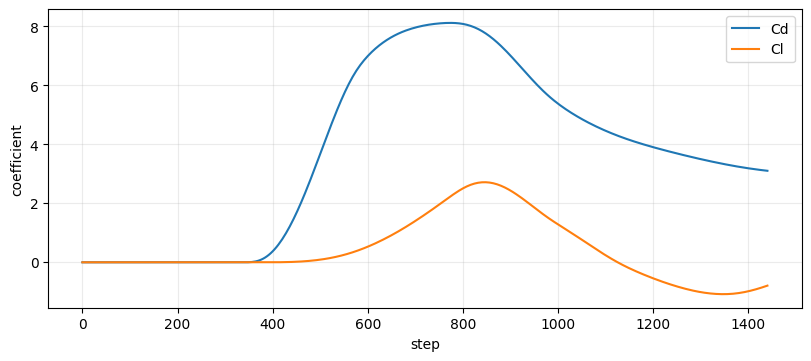

In [ ]:
forces_path = data_dir / 'forces.csv'
if forces_path.exists() and forces_path.stat().st_size > 0:
    forces = np.genfromtxt(forces_path, delimiter=',', names=True)
    if forces.shape != () and forces.size > 1:
        fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
        ax.plot(forces['step'], forces['Cd'], label='Cd')
        ax.plot(forces['step'], forces['Cl'], label='Cl')
        ax.set_xlabel('step')
        ax.set_ylabel('coefficient')
        ax.grid(True, alpha=0.25)
        ax.legend()
        plt.show()
    else:
        print('forces.csv has fewer than two samples')
else:
    print('forces.csv not found')

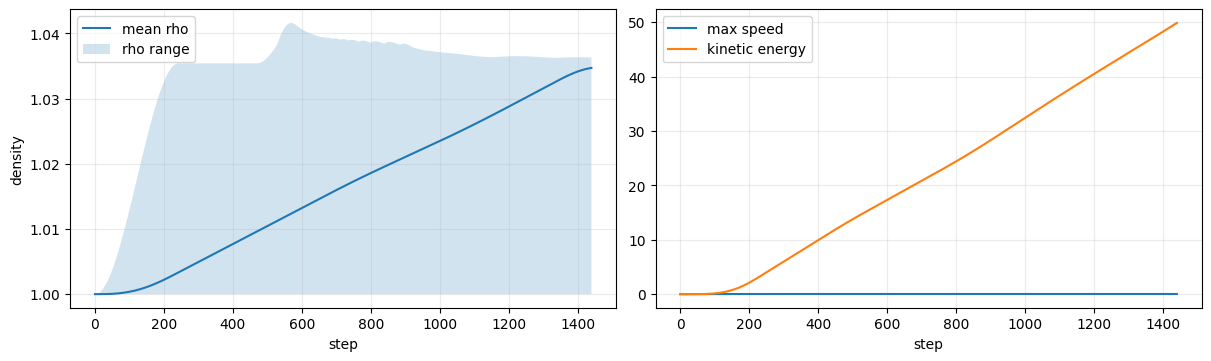

In [ ]:
diagnostics_path = data_dir / 'diagnostics.csv'
if diagnostics_path.exists() and diagnostics_path.stat().st_size > 0:
    diag = np.genfromtxt(diagnostics_path, delimiter=',', names=True)
    if diag.shape != () and diag.size > 1:
        fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
        ax[0].plot(diag['step'], diag['mean_rho'], label='mean rho')
        ax[0].fill_between(diag['step'], diag['min_rho'], diag['max_rho'], alpha=0.2, label='rho range')
        ax[0].set_xlabel('step')
        ax[0].set_ylabel('density')
        ax[0].grid(True, alpha=0.25)
        ax[0].legend()

        ax[1].plot(diag['step'], diag['max_speed'], label='max speed')
        ax[1].plot(diag['step'], diag['kinetic_energy'], label='kinetic energy')
        ax[1].set_xlabel('step')
        ax[1].grid(True, alpha=0.25)
        ax[1].legend()
        plt.show()
    else:
        print('diagnostics.csv has fewer than two samples')
else:
    print('diagnostics.csv not found')

## Formula 1 + GPU benchmark

This section can run or reuse the Formula 1 case, then benchmarks the three LBM step implementations on the same solid mask: CPU reference, naive GPU AoS, and optimized GPU SoA.

In [ ]:

import json
from pathlib import Path
import subprocess
from IPython.display import display, Markdown

project_root = Path('..').resolve()
formula1_dir = project_root / 'resultados' / 'formula1'

# Builds the presentation F1 case automatically if resultados/formula1 is missing.
# The Makefile target exports many frames, so the first run can take a while and use several GB.
AUTO_BUILD_F1_IF_MISSING = True
RUN_F1_GPU_BENCHMARK = True
F1_BENCHMARK_STEPS = 600


def run_project_command(args):
    args = [str(arg) for arg in args]
    print('$ ' + ' '.join(args))
    completed = subprocess.run(
        args,
        cwd=project_root,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
    )
    print(completed.stdout)
    if completed.returncode != 0:
        raise RuntimeError(f'Command failed with exit code {completed.returncode}: {args}')
    return completed


if AUTO_BUILD_F1_IF_MISSING and not (formula1_dir / 'metadata.json').exists():
    run_project_command(['make', 'formula1'])

if not (formula1_dir / 'metadata.json').exists():
    raise FileNotFoundError(
        'Missing resultados/formula1. Run `make formula1` in a terminal or set AUTO_BUILD_F1_IF_MISSING=True.'
    )

f1_case_dir = formula1_dir
with (f1_case_dir / 'metadata.json').open() as f:
    f1_meta = json.load(f)

f1_frame_paths = sorted((f1_case_dir / 'frames').glob('frame_*.bin'))
if not f1_frame_paths:
    raise FileNotFoundError(f'No Formula 1 frames found in {f1_case_dir / "frames"}')

solid_frame = f1_case_dir / 'frames' / 'frame_000000.bin'
benchmark_exe = project_root / 'ejecuciones' / 'build' / 'lbm_gpu_benchmark'
if RUN_F1_GPU_BENCHMARK:
    if not benchmark_exe.exists():
        run_project_command(['make', 'ejecuciones/build/lbm_gpu_benchmark'])
    run_project_command([
        benchmark_exe,
        '--nx', int(f1_meta['nx']),
        '--ny', int(f1_meta['ny']),
        '--steps', F1_BENCHMARK_STEPS,
        '--solid-frame', solid_frame,
        '--solid-field-index', 5,
        '--output', f1_case_dir,
    ])

display(Markdown(
    f'Using Formula 1 case: `{f1_case_dir.relative_to(project_root)}`  '\
    f'\nGrid: `{f1_meta["nx"]}x{f1_meta["ny"]}`  '\
    f'\nFrames: `{len(f1_frame_paths)}`  '\
    f'\nLast frame: `{f1_frame_paths[-1].name}`  '\
    f'\nGPU benchmark steps: `{F1_BENCHMARK_STEPS}`'
))


In [ ]:

from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


def load_kernel_timings(case_dir):
    timings_path = Path(case_dir) / 'gpu_kernel_timings.csv'
    if not timings_path.exists():
        raise FileNotFoundError(f'Missing timings CSV: {timings_path}')
    rows = []
    with timings_path.open(newline='') as f:
        reader = csv.DictReader(f)
        for row in reader:
            parsed = dict(row)
            for key in [
                'nx', 'ny', 'steps', 'cells', 'h2d_ms', 'kernel_ms', 'd2h_ms',
                'total_ms', 'mlups', 'max_abs_rho', 'mean_abs_rho', 'max_abs_ux',
                'mean_abs_ux', 'max_abs_uy', 'mean_abs_uy', 'max_abs_f', 'mean_abs_f'
            ]:
                parsed[key] = float(parsed[key])
            rows.append(parsed)
    return timings_path, rows


def markdown_table(rows, columns):
    header = '| ' + ' | '.join(columns) + ' |'
    sep = '| ' + ' | '.join(['---'] * len(columns)) + ' |'
    body = []
    for row in rows:
        values = []
        for col in columns:
            value = row[col]
            if isinstance(value, float):
                if col in ('kernel_ms', 'total_ms', 'h2d_ms', 'd2h_ms'):
                    values.append(f'{value:.3f}')
                elif col == 'mlups':
                    values.append(f'{value:.1f}')
                elif col.startswith('speedup'):
                    values.append(f'{value:.1f}x')
                elif col.startswith('max_abs') or col.startswith('mean_abs'):
                    values.append(f'{value:.2e}')
                else:
                    values.append(f'{value:g}')
            else:
                values.append(str(value))
        body.append('| ' + ' | '.join(values) + ' |')
    return '\n'.join([header, sep] + body)


timings_path, timing_rows = load_kernel_timings(f1_case_dir)
labels = {
    'cpu_reference': 'CPU',
    'gpu_aos_naive': 'GPU AOS naive',
    'gpu_soa_optimized': 'GPU SOA opt',
}
for row in timing_rows:
    row['label'] = labels.get(row['backend'], row['backend'])

cpu_row = next(row for row in timing_rows if row['backend'] == 'cpu_reference')
aos_row = next(row for row in timing_rows if row['backend'] == 'gpu_aos_naive')
soa_row = next(row for row in timing_rows if row['backend'] == 'gpu_soa_optimized')

for row in timing_rows:
    row['speedup_vs_cpu_kernel'] = cpu_row['kernel_ms'] / row['kernel_ms'] if row['kernel_ms'] else 0.0
    row['speedup_vs_cpu_total'] = cpu_row['total_ms'] / row['total_ms'] if row['total_ms'] else 0.0

soa_vs_aos = aos_row['kernel_ms'] / soa_row['kernel_ms'] if soa_row['kernel_ms'] else 0.0
summary = (
    f'`{timings_path.relative_to(project_root)}`\n\n'
    f'- GPU AOS naive vs CPU kernel: **{aos_row["speedup_vs_cpu_kernel"]:.1f}x**\n'
    f'- GPU SOA optimized vs CPU kernel: **{soa_row["speedup_vs_cpu_kernel"]:.1f}x**\n'
    f'- SOA optimized vs AOS naive kernel: **{soa_vs_aos:.2f}x**\n'
)
display(Markdown(summary))

display(Markdown(markdown_table(
    timing_rows,
    ['label', 'layout', 'kernel_ms', 'total_ms', 'mlups', 'speedup_vs_cpu_kernel', 'max_abs_rho', 'max_abs_ux', 'max_abs_uy']
)))

fig, ax = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
x = np.arange(len(timing_rows))
bar_colors = ['#565656', '#c65a38', '#2878b5']
labels_x = [row['label'] for row in timing_rows]

ax[0].bar(x, [row['kernel_ms'] for row in timing_rows], color=bar_colors)
ax[0].set_yscale('log')
ax[0].set_xticks(x, labels_x, rotation=15, ha='right')
ax[0].set_ylabel('kernel time [ms, log]')
ax[0].set_title('Kernel time')
ax[0].grid(True, axis='y', alpha=0.25)
for i, row in enumerate(timing_rows):
    ax[0].text(i, row['kernel_ms'], f'{row["kernel_ms"]:.1f}', ha='center', va='bottom', fontsize=9)

ax[1].bar(x, [row['mlups'] for row in timing_rows], color=bar_colors)
ax[1].set_xticks(x, labels_x, rotation=15, ha='right')
ax[1].set_ylabel('MLUPS')
ax[1].set_title('Throughput')
ax[1].grid(True, axis='y', alpha=0.25)
for i, row in enumerate(timing_rows):
    ax[1].text(i, row['mlups'], f'{row["mlups"]:.0f}', ha='center', va='bottom', fontsize=9)

ax[2].bar(x, [row['speedup_vs_cpu_kernel'] for row in timing_rows], color=bar_colors)
ax[2].set_xticks(x, labels_x, rotation=15, ha='right')
ax[2].set_ylabel('speedup vs CPU')
ax[2].set_title('Kernel speedup')
ax[2].grid(True, axis='y', alpha=0.25)
for i, row in enumerate(timing_rows):
    ax[2].text(i, row['speedup_vs_cpu_kernel'], f'{row["speedup_vs_cpu_kernel"]:.1f}x', ha='center', va='bottom', fontsize=9)

plt.show()


In [ ]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


def read_case_frame(case_dir, frame_index=-1):
    case_dir = Path(case_dir)
    with (case_dir / 'metadata.json').open() as f:
        case_meta = json.load(f)
    nx_case = int(case_meta['nx'])
    ny_case = int(case_meta['ny'])
    field_names = list(case_meta['fields'])
    frames = sorted((case_dir / 'frames').glob('frame_*.bin'))
    if not frames:
        raise FileNotFoundError(f'No frames found in {case_dir / "frames"}')
    frame_path = frames[frame_index]
    cells = nx_case * ny_case
    raw = np.fromfile(frame_path, dtype=np.float32)
    expected = len(field_names) * cells
    if raw.size != expected:
        raise ValueError(f'{frame_path.name} has {raw.size} floats, expected {expected}')
    arrays = {
        name: raw[i * cells:(i + 1) * cells].reshape(ny_case, nx_case)
        for i, name in enumerate(field_names)
    }
    return case_meta, frames, frame_path, arrays


def f1_frame_step(path):
    return int(Path(path).stem.split('_')[-1])


def f1_inlet_velocity(case_meta, step):
    u = float(case_meta.get('u_in', 1.0))
    ramp = int(case_meta.get('inlet_ramp_steps', 0))
    if ramp <= 0:
        return u
    t = np.clip(step / ramp, 0.0, 1.0)
    smooth = t * t * (3.0 - 2.0 * t)
    return u * smooth


def f1_crop_limits(arrays, case_meta, mode='vehicle+wake'):
    solid = arrays['solid'] > 0.5
    ys, xs = np.where(solid)
    nx_case = int(case_meta['nx'])
    ny_case = int(case_meta['ny'])
    if mode == 'full' or xs.size == 0:
        return None
    xmin, xmax = int(xs.min()), int(xs.max())
    ymin, ymax = int(ys.min()), int(ys.max())
    length = max(1, xmax - xmin + 1)
    height = max(1, ymax - ymin + 1)
    if mode == 'vehicle':
        pad_x0, pad_x1 = int(0.35 * length), int(0.55 * length)
        pad_y = int(4.0 * height)
    else:
        pad_x0, pad_x1 = int(0.55 * length), int(0.75 * length)
        pad_y = int(5.0 * height)
    return (
        max(0, xmin - pad_x0),
        min(nx_case - 1, xmax + pad_x1),
        max(0, ymin - pad_y),
        min(ny_case - 1, ymax + pad_y),
    )


def f1_flow_reference(arrays, limits, wall_band=5.0):
    speed = np.hypot(arrays['ux'], arrays['uy'])
    solid = arrays['solid'] > 0.5
    if limits is None:
        x0, x1, y0, y1 = 0, speed.shape[1] - 1, 0, speed.shape[0] - 1
    else:
        x0, x1, y0, y1 = limits
    ys, xs = np.where(solid)
    if xs.size:
        xmin = int(xs.min())
        length = max(1, int(xs.max()) - xmin + 1)
        ref_x1 = max(x0, min(x1, xmin - int(0.12 * length)))
    else:
        ref_x1 = x0 + max(1, int(0.25 * (x1 - x0 + 1)))
    region = np.s_[y0:y1 + 1, x0:ref_x1 + 1]
    mask = solid[region] | (arrays['phi'][region] < wall_band)
    values = np.ma.array(speed[region], mask=mask).compressed()
    values = values[np.isfinite(values)]
    if values.size >= 16:
        return float(np.nanmedian(values))
    return max(float(f1_meta.get('u_in', 1.0)), 1.0e-6)


def f1_scalar_view(arrays, case_meta, field_name, limits, contrast=0.24, wall_band=5.0):
    speed = np.hypot(arrays['ux'], arrays['uy'])
    solid = arrays['solid'] > 0.5
    u_ref = max(f1_flow_reference(arrays, limits, wall_band), 1.0e-6)
    if field_name == 'speed_deviation':
        return speed / u_ref - 1.0, 'RdBu_r', -contrast, contrast
    if field_name == 'speed_ratio':
        return speed / u_ref, 'inferno', 0.0, 1.45
    if field_name == 'speed':
        return speed, 'magma', 0.0, max(1.35 * float(case_meta.get('u_in', 1.0)), np.nanpercentile(speed[~solid], 99.0))
    if field_name == 'vorticity':
        values = arrays['vorticity']
        finite = values[np.isfinite(values) & ~solid]
        vmax = np.nanpercentile(np.abs(finite), 99.2) if finite.size else 0.02
        return values, 'coolwarm', -vmax, vmax
    return arrays[field_name], 'viridis', None, None


def f1_overlay(ax, arrays, limits, case_meta, mode='quiver', wall_band=5.0):
    if mode == 'none':
        return
    if limits is None:
        x0, x1, y0, y1 = 0, arrays['ux'].shape[1] - 1, 0, arrays['ux'].shape[0] - 1
    else:
        x0, x1, y0, y1 = limits
    u_ref = f1_flow_reference(arrays, limits, wall_band)
    if u_ref <= 1.0e-8:
        return
    width = max(1, x1 - x0 + 1)
    height = max(1, y1 - y0 + 1)
    step = max(3, int(max(width, height) / 85))
    xs = np.arange(x0, x1 + 1, step)
    ys = np.arange(y0, y1 + 1, step)
    ux = arrays['ux'][y0:y1 + 1:step, x0:x1 + 1:step]
    uy = arrays['uy'][y0:y1 + 1:step, x0:x1 + 1:step]
    speed = np.hypot(ux, uy)
    mask = (arrays['solid'][y0:y1 + 1:step, x0:x1 + 1:step] > 0.5)
    mask = mask | (arrays['phi'][y0:y1 + 1:step, x0:x1 + 1:step] < wall_band)
    mask = mask | (speed < max(0.18 * u_ref, 1.0e-8))
    if np.count_nonzero(~mask) < 8:
        return
    ux = np.ma.array(ux, mask=mask)
    uy = np.ma.array(uy, mask=mask)
    if mode == 'quiver':
        qstep = max(1, int(max(width, height) / 34 / step))
        ax.quiver(
            xs[::qstep], ys[::qstep], ux[::qstep, ::qstep], uy[::qstep, ::qstep],
            color='black', alpha=0.45, scale_units='xy', angles='xy',
            scale=max(0.006, 0.24 * u_ref), width=0.0021,
        )
    elif mode == 'streamlines':
        X, Y = np.meshgrid(xs, ys)
        ax.streamplot(X, Y, ux, uy, color='white', density=1.15, linewidth=0.7, arrowsize=0.75)


def plot_f1_frame(frame_index=0, field_name='speed_deviation', view_mode='vehicle+wake', overlay_mode='quiver', contrast=0.24, wall_band=5.0):
    case_meta, frames, frame_path, arrays = read_case_frame(f1_case_dir, frame_index)
    step = f1_frame_step(frame_path)
    limits = f1_crop_limits(arrays, case_meta, view_mode)
    data, cmap_name, vmin, vmax = f1_scalar_view(arrays, case_meta, field_name, limits, contrast, wall_band)
    solid = arrays['solid'] > 0.5
    mask = solid | (arrays['phi'] < wall_band if field_name not in ('solid', 'phi', 'vorticity') else solid)
    shown = np.ma.array(data, mask=mask if field_name != 'solid' else None)

    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad(color='0.82')
    fig, ax = plt.subplots(figsize=(10.5, 4.1), constrained_layout=True)
    im = ax.imshow(shown, origin='lower', cmap=cmap, vmin=vmin, vmax=vmax, interpolation='bicubic')
    if field_name == 'speed_deviation':
        pos = np.ma.masked_where(shown <= 0.10, shown)
        neg = np.ma.masked_where(shown >= -0.10, shown)
        try:
            ax.contour(pos, levels=[0.10, 0.18], colors=['#ff7a45', '#b21b1b'], linewidths=[0.9, 1.2], alpha=0.9)
            ax.contour(neg, levels=[-0.18, -0.10], colors=['#214fba', '#53a6ff'], linewidths=[1.2, 0.9], alpha=0.9)
        except ValueError:
            pass
    ax.contour(solid.astype(float), levels=[0.5], colors='black', linewidths=1.0)
    if limits is not None:
        x0, x1, y0, y1 = limits
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
    f1_overlay(ax, arrays, limits, case_meta, overlay_mode, wall_band)
    ax.set_title(f'Formula 1 {field_name} - {frame_path.name} - Uin={f1_inlet_velocity(case_meta, step):.4f}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    plt.show()


display(Markdown(f'Formula 1 animation frames: **{len(f1_frame_paths)}**. Use `speed_deviation` for red/blue relative speed.'))

try:
    import ipywidgets as widgets

    f1_frame_slider = widgets.IntSlider(
        value=min(len(f1_frame_paths) - 1, max(0, int(0.55 * len(f1_frame_paths)))),
        min=0,
        max=len(f1_frame_paths) - 1,
        step=1,
        description='frame',
        continuous_update=False,
        layout=widgets.Layout(width='540px'),
    )
    f1_play = widgets.Play(value=0, min=0, max=len(f1_frame_paths) - 1, step=1, interval=70)
    widgets.jslink((f1_play, 'value'), (f1_frame_slider, 'value'))
    f1_field = widgets.Dropdown(options=['speed_deviation', 'speed_ratio', 'speed', 'vorticity'], value='speed_deviation', description='field')
    f1_view = widgets.Dropdown(options=['vehicle+wake', 'vehicle', 'full'], value='vehicle+wake', description='view')
    f1_overlay_mode = widgets.Dropdown(options=['quiver', 'streamlines', 'none'], value='quiver', description='flow')
    f1_contrast = widgets.FloatSlider(value=0.24, min=0.08, max=0.60, step=0.02, description='range', continuous_update=False, layout=widgets.Layout(width='360px'))
    f1_wall = widgets.FloatSlider(value=5.0, min=0.0, max=18.0, step=0.5, description='wall band', continuous_update=False, layout=widgets.Layout(width='360px'))
    f1_controls = widgets.VBox([
        widgets.HBox([f1_play, f1_frame_slider, f1_field]),
        widgets.HBox([f1_view, f1_overlay_mode, f1_contrast, f1_wall]),
    ])
    f1_out = widgets.interactive_output(
        plot_f1_frame,
        {
            'frame_index': f1_frame_slider,
            'field_name': f1_field,
            'view_mode': f1_view,
            'overlay_mode': f1_overlay_mode,
            'contrast': f1_contrast,
            'wall_band': f1_wall,
        },
    )
    display(f1_controls, f1_out)
except Exception as exc:
    print(f'ipywidgets unavailable: {exc}')
    plot_f1_frame(len(f1_frame_paths) - 1)
